# TP4: Denoising in the time-frequency domain

We have a clean music signal music.wav and the three noises from the random signals chapter (noise1.wav, noise2.wav, noise3.wav). The 4 files are at 16 kHz, mono, 16 bits, and all last 8.75 s. We convert them to floats by dividing by 32768.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display

fs, music = wavfile.read("data/music.wav")
music = music.astype(float) / 32768

fs, noise1 = wavfile.read("data/noise1.wav")
fs, noise2 = wavfile.read("data/noise2.wav")
fs, noise3 = wavfile.read("data/noise3.wav")
noises = [noise1.astype(float) / 32768, noise2.astype(float) / 32768, noise3.astype(float) / 32768]
names = ["noise1", "noise2", "noise3"]

## 1. Noisy signals

**Question 1:** simulate noisy versions of the music with the three noises, at several SNR levels.

We use the following definition of the SNR: $SNR(z|x)=20\log_{10}\left(\frac{\|x\|}{\|z-x\|}\right)$. To get an SNR of $r$ dB, we multiply the noise $n$ by a factor $c$:

$$20\log_{10}\left(\frac{\|x\|}{c\|n\|}\right)=r \quad\Longrightarrow\quad c=\frac{\|x\|}{\|n\|\,10^{r/20}}$$

We take six levels: -5, 0, 5, 10, 15 and 20 dB, which gives 18 noisy signals. Since the noise is a fixed file, we get exactly the SNR we want.

In [2]:
def snr(ref, result):
    return 20 * np.log10(np.linalg.norm(ref) / np.linalg.norm(result - ref))


targets = [-5, 0, 5, 10, 15, 20]
scaled_noises = []
for k in range(3):
    row = []
    for target in targets:
        c = np.linalg.norm(music) / (np.linalg.norm(noises[k]) * 10**(target / 20))
        row.append(c * noises[k])
    scaled_noises.append(row)

for k in range(3):
    text = ""
    for i in range(6):
        text = text + f"{snr(music, music + scaled_noises[k][i]):.2f} dB  "
    print(names[k], ":", text)

noise1 : -5.00 dB  0.00 dB  5.00 dB  10.00 dB  15.00 dB  20.00 dB  
noise2 : -5.00 dB  0.00 dB  5.00 dB  10.00 dB  15.00 dB  20.00 dB  
noise3 : -5.00 dB  -0.00 dB  5.00 dB  10.00 dB  15.00 dB  20.00 dB  


## 2. Denoising in the STFT domain

**Question 2:** implement the denoising by hard thresholding and spectral subtraction.

### 2.1 STFT and noise spectrum

For the STFT, we use scipy.signal.stft with a Hann window of $L=1024$ samples, which is 64 ms at 16 kHz, and 75% overlap, so a hop of 256 samples. To go back to the signal, scipy.signal.istft uses the dual window. We first check that we get back the original signal.

In the STFT domain we have $Y=X+N$. We fix the music and take the average over the noise, which we assume is centered. So the cross term $2\,\text{Re}(X\,\overline{\mathbb E[N]})$ is 0 and we get:

$$\mathbb E|Y[\tau,\nu]|^2=|X[\tau,\nu]|^2+S_n[\nu],\qquad S_n[\nu]=\mathbb E|N[\tau,\nu]|^2$$

The noise is stationary, so $S_n$ does not depend on the time $\tau$. To estimate it, we average $|N[\tau,\nu]|^2$ over all the frames, like in Welch's method. Here we have the noise file, so we compute $S_n$ directly on it. In a real case, we would have to estimate it on a part where there is no music.

We plot $S_n$ for the three noises at 0 dB, with the average power of the music. To find the color of the noises, we measure the slope of $S_n$ in dB per decade, between 50 and 500 Hz for the low frequencies and between 2 and 7 kHz for the high frequencies. A spectrum in $1/\nu^\beta$ gives a slope of $-10\beta$ dB per decade, so 0 for a white noise and -10 for a pink noise.

Maximum reconstruction error: 4.440892098500626e-16
noise1 : slope -0.0 dB per decade between 50 and 500 Hz, 0.1 dB per decade between 2 and 7 kHz
noise2 : slope -10.1 dB per decade between 50 and 500 Hz, -10.0 dB per decade between 2 and 7 kHz
noise3 : slope -7.9 dB per decade between 50 and 500 Hz, -1.6 dB per decade between 2 and 7 kHz


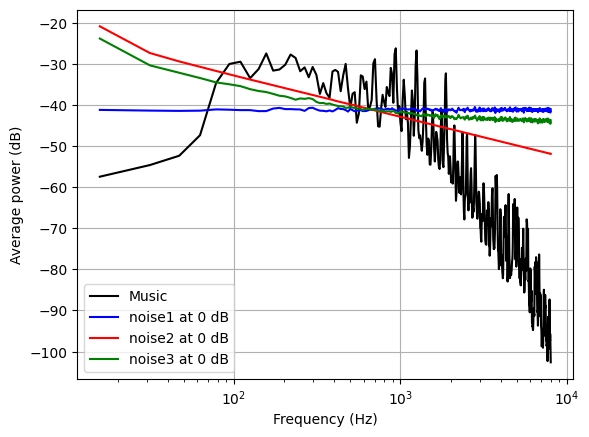

In [3]:
L = 1024
hop = 256


def stft(x, L, hop):
    f, t, X = signal.stft(x, fs, window="hann", nperseg=L, noverlap=L - hop)
    return X


def istft(X, L, hop):
    t, x = signal.istft(X, fs, window="hann", nperseg=L, noverlap=L - hop)
    return x[:len(music)]


def noise_spectrum(noise, L, hop):
    N = stft(noise, L, hop)
    return np.mean(np.abs(N)**2, axis=1)


error = np.max(np.abs(istft(stft(music, L, hop), L, hop) - music))
print("Maximum reconstruction error:", error)

freqs, times, X = signal.stft(music, fs, window="hann", nperseg=L, noverlap=L - hop)
music_power = np.mean(np.abs(X)**2, axis=1)
low = (freqs > 50) & (freqs < 500)
high = (freqs > 2000) & (freqs < 7000)
colors = ["b", "r", "g"]

plt.semilogx(freqs[1:], 10 * np.log10(music_power[1:]), "k", label="Music")
for k in range(3):
    Sn = noise_spectrum(scaled_noises[k][1], L, hop)
    plt.semilogx(freqs[1:], 10 * np.log10(Sn[1:]), colors[k], label=names[k] + " at 0 dB")
    slope_low = np.polyfit(np.log10(freqs[low]), 10 * np.log10(Sn[low]), 1)[0]
    slope_high = np.polyfit(np.log10(freqs[high]), 10 * np.log10(Sn[high]), 1)[0]
    print(names[k], ": slope", round(slope_low, 1), "dB per decade between 50 and 500 Hz,", round(slope_high, 1), "dB per decade between 2 and 7 kHz")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Average power (dB)")
plt.legend()
plt.grid()
plt.show()

For noise1, the slope is zero in both bands, so it is a white noise. For noise2, it is -10 dB per decade in both bands, so it is a pink noise. For noise3, the slope is about -8 dB per decade at low frequencies, which is close to a pink noise, but it is almost zero at high frequencies, like for a white noise. So it is a mix of both.

At 0 dB, the noises have the same energy as the music, but it is not spread the same way. The music is mostly between 100 Hz and 1 kHz and it drops a lot above 2 kHz. So above 1 to 2 kHz depending on the noise, the noise is stronger than the music. The pink noise is very strong at low frequencies, where the music is. This is why we use a threshold that changes with the frequency, with $S_n[\nu]$.

### 2.2 The two denoising rules

$S_n$ is a power, but in the two rules we compare $|Y|$, which is an amplitude. So we use the noise amplitude $\sigma_n[\nu]=\sqrt{S_n[\nu]}$, and the threshold is a multiple of this amplitude.

**Hard thresholding**: we keep the coefficient only if it is above the threshold.

$$\hat X[\tau,\nu]=\begin{cases}Y[\tau,\nu] & \text{if } |Y[\tau,\nu]|>\lambda\,\sigma_n[\nu]\\ 0 & \text{otherwise}\end{cases}$$

**Spectral subtraction**: we reduce each coefficient.

$$\hat X[\tau,\nu]=Y[\tau,\nu]\left(1-\lambda\,\frac{\sigma_n[\nu]^2}{|Y[\tau,\nu]|^2}\right)_+$$

With $\lambda=1$, it is actually a Wiener filter at each time-frequency point. The Wiener gain is $|X|^2/(|X|^2+S_n)$, and with the relation above we can estimate $|X|^2$ by $|Y|^2-S_n$. By replacing:

$$\frac{|Y|^2-S_n}{(|Y|^2-S_n)+S_n}=1-\frac{S_n}{|Y|^2}$$

The $(\cdot)_+$ is there to avoid a negative gain, and taking $\lambda>1$ means removing more than the average noise power. Hard thresholding keeps the coefficients above the threshold without changing them, while spectral subtraction reduces all the coefficients, and more when they are close to the noise level.

In [4]:
def hard_thresholding(y, noise_power, lam, L, hop):
    Y = stft(y, L, hop)
    sigma = np.sqrt(noise_power)
    mask = np.zeros(Y.shape)
    for t in range(Y.shape[1]):
        mask[:, t] = np.abs(Y[:, t]) > lam * sigma
    return istft(mask * Y, L, hop)


def spectral_subtraction(y, noise_power, lam, L, hop):
    Y = stft(y, L, hop)
    gain = np.zeros(Y.shape)
    for t in range(Y.shape[1]):
        gain[:, t] = 1 - lam * noise_power / np.abs(Y[:, t])**2
    gain = np.maximum(gain, 0)
    return istft(gain * Y, L, hop)

## 3. Denoising the noisy versions

**Question 3:** denoise the 18 noisy versions with the two methods.

We choose $\lambda$ by plotting the SNR we get as a function of $\lambda$, for $\lambda$ from 0.5 to 4. Then we print for each case the best $\lambda$ and the SNR obtained with each method.

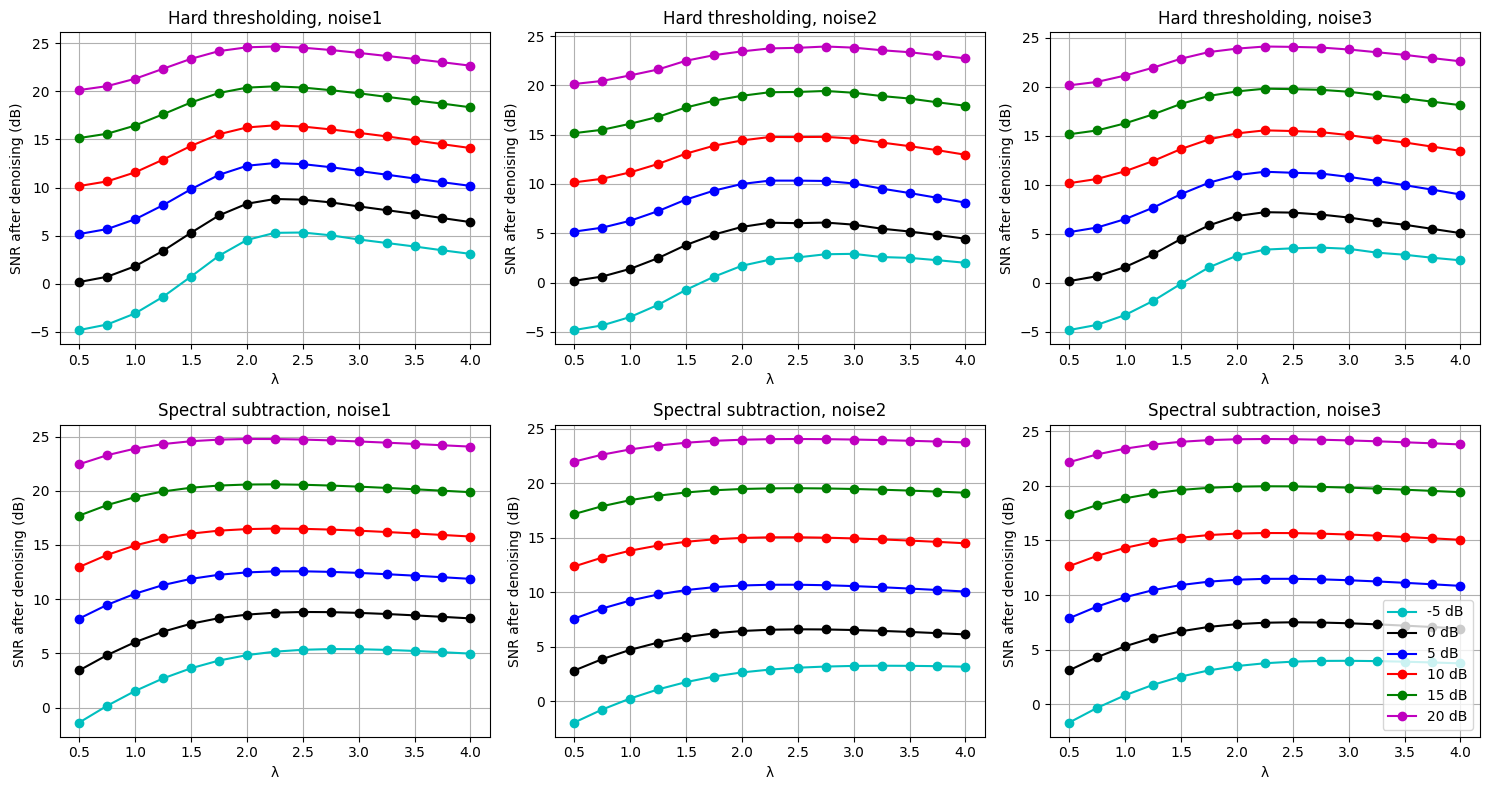

noise1 -5 dB: hard thresholding 5.32 dB with λ = 2.5 / spectral subtraction 5.39 dB with λ = 2.75
noise1 0 dB: hard thresholding 8.81 dB with λ = 2.25 / spectral subtraction 8.82 dB with λ = 2.5
noise1 5 dB: hard thresholding 12.54 dB with λ = 2.25 / spectral subtraction 12.57 dB with λ = 2.5
noise1 10 dB: hard thresholding 16.46 dB with λ = 2.25 / spectral subtraction 16.51 dB with λ = 2.25
noise1 15 dB: hard thresholding 20.52 dB with λ = 2.25 / spectral subtraction 20.59 dB with λ = 2.25
noise1 20 dB: hard thresholding 24.66 dB with λ = 2.25 / spectral subtraction 24.77 dB with λ = 2.0
noise2 -5 dB: hard thresholding 2.92 dB with λ = 3.0 / spectral subtraction 3.27 dB with λ = 3.25
noise2 0 dB: hard thresholding 6.09 dB with λ = 2.75 / spectral subtraction 6.61 dB with λ = 2.5
noise2 5 dB: hard thresholding 10.34 dB with λ = 2.25 / spectral subtraction 10.69 dB with λ = 2.5
noise2 10 dB: hard thresholding 14.77 dB with λ = 2.75 / spectral subtraction 15.04 dB with λ = 2.5
noise2 15 

In [5]:
lams = np.arange(0.5, 4.01, 0.25)
results_hard = np.zeros((3, 6, len(lams)))
results_ss = np.zeros((3, 6, len(lams)))
for k in range(3):
    for i in range(6):
        noise = scaled_noises[k][i]
        noisy = music + noise
        Sn = noise_spectrum(noise, L, hop)
        for j in range(len(lams)):
            results_hard[k, i, j] = snr(music, hard_thresholding(noisy, Sn, lams[j], L, hop))
            results_ss[k, i, j] = snr(music, spectral_subtraction(noisy, Sn, lams[j], L, hop))

level_colors = ["c", "k", "b", "r", "g", "m"]
plt.figure(figsize=(15, 8))
for k in range(3):
    plt.subplot(2, 3, k + 1)
    for i in range(6):
        plt.plot(lams, results_hard[k, i], "-o", color=level_colors[i], label=str(targets[i]) + " dB")
    plt.title("Hard thresholding, " + names[k])
    plt.xlabel("λ")
    plt.ylabel("SNR after denoising (dB)")
    plt.grid()

    plt.subplot(2, 3, k + 4)
    for i in range(6):
        plt.plot(lams, results_ss[k, i], "-o", color=level_colors[i], label=str(targets[i]) + " dB")
    plt.title("Spectral subtraction, " + names[k])
    plt.xlabel("λ")
    plt.ylabel("SNR after denoising (dB)")
    plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

for k in range(3):
    for i in range(6):
        j_hard = np.argmax(results_hard[k, i])
        j_ss = np.argmax(results_ss[k, i])
        print(names[k], targets[i], "dB: hard thresholding", round(results_hard[k, i, j_hard], 2), "dB with λ =", lams[j_hard],
              "/ spectral subtraction", round(results_ss[k, i, j_ss], 2), "dB with λ =", lams[j_ss])

What we see on the curves and in the results:
- both methods improve the SNR in the 18 cases
- spectral subtraction does a bit better than hard thresholding every time, but not by much, at most about 0.5 dB for noise2 at 0 dB
- the higher the starting SNR, the less we gain, for example with noise1 about 10 dB at -5 dB but less than 5 dB at 20 dB
- the white noise is the best removed, then noise3, then noise2

## 4. Discussion of the parameters

**Question 4:** discuss the parameters.

### 4.1 The threshold $\lambda$

If $\lambda$ is too small we let noise through, and if it is too big we also remove music. On the curves, the best $\lambda$ is around 2.5 for both methods.

When writing the two rules, we expected spectral subtraction to be less sensitive to the choice of $\lambda$, because it reduces the coefficients instead of cutting them. Its curves are indeed much flatter. For noise1 at 0 dB and $\lambda$ = 1, we read about 2 dB for hard thresholding against 6 dB for spectral subtraction.

We still need to understand why the best $\lambda$ is much larger than 1. For this we look at the noise alone, whose power $|N|^2$ varies around its mean $S_n$. We count, for noise1 at 0 dB, the share of noise points that pass the threshold. For hard thresholding, a point passes if $|N|>\lambda\sigma_n$, that is if $|N|^2>\lambda^2S_n$. For spectral subtraction, the gain is not zero if $|N|^2>\lambda S_n$.

In [6]:
noise = scaled_noises[0][1]
N = stft(noise, L, hop)
Sn = noise_spectrum(noise, L, hop)
for lam in [1, 1.5, 2, 2.5, 3]:
    count_hard = 0
    count_ss = 0
    for t in range(N.shape[1]):
        count_hard = count_hard + np.sum(np.abs(N[:, t])**2 > lam**2 * Sn)
        count_ss = count_ss + np.sum(np.abs(N[:, t])**2 > lam * Sn)
    print("λ =", lam, ": hard thresholding", round(100 * count_hard / N.size, 1), "%, spectral subtraction", round(100 * count_ss / N.size, 1), "%")

λ = 1 : hard thresholding 37.0 %, spectral subtraction 37.0 %
λ = 1.5 : hard thresholding 10.5 %, spectral subtraction 22.4 %
λ = 2 : hard thresholding 1.7 %, spectral subtraction 13.6 %
λ = 2.5 : hard thresholding 0.2 %, spectral subtraction 8.2 %
λ = 3 : hard thresholding 0.0 %, spectral subtraction 4.9 %


With $\lambda$ = 1, more than a third of the noise points pass the threshold (37%), whatever the method.

Around $\lambda$ = 2.5, hard thresholding lets almost none of them through (0.2%) against about 8% for spectral subtraction, but spectral subtraction reduces them a lot, since its gain is almost zero just above the threshold, while hard thresholding keeps the few points that pass as they are. These isolated points in the time-frequency plane give what is called musical noise, that is short little sounds at random frequencies.

Since hard thresholding keeps or removes each coefficient with nothing in between, a $\lambda$ that is too small lets a lot of noise through without reducing it, and a $\lambda$ that is too big removes pieces of notes.

### 4.2 Window length and overlap

We change $L$ from 128 to 4096 samples, so from 8 to 256 ms, and we compare an overlap of 50% and 75%, at 0 and 20 dB, for both methods. We compute the noise spectrum again with the same settings as the STFT. For each setting, we keep the best $\lambda$ among 1.5, 2, 2.5 and 3, which are around the values found before

Hard thresholding noise1 0 dB, overlap 75 %: 6.56  7.17  7.94  8.74  9.64  10.09  
Hard thresholding noise1 0 dB, overlap 50 %: 5.81  6.54  7.34  8.11  9.0  9.44  


Hard thresholding noise1 20 dB, overlap 75 %: 23.64  23.89  24.26  24.57  24.75  24.8  
Hard thresholding noise1 20 dB, overlap 50 %: 23.24  23.5  23.78  24.05  24.16  24.19  


Hard thresholding noise2 0 dB, overlap 75 %: 3.9  4.76  5.46  6.03  7.3  8.03  
Hard thresholding noise2 0 dB, overlap 50 %: 3.37  4.25  4.93  5.41  6.33  7.57  


Hard thresholding noise2 20 dB, overlap 75 %: 20.49  22.33  23.65  23.82  23.97  23.92  
Hard thresholding noise2 20 dB, overlap 50 %: 20.12  21.6  23.24  23.31  23.34  23.39  


Hard thresholding noise3 0 dB, overlap 75 %: 4.59  5.65  6.44  7.15  8.44  8.89  
Hard thresholding noise3 0 dB, overlap 50 %: 3.98  5.08  5.88  6.58  7.46  8.32  


...

Spectral subtraction noise1 20 dB, overlap 75 %: 23.79  24.04  24.41  24.77  24.96  24.99  
Spectral subtraction noise1 20 dB, overlap 50 %: 23.58  23.83  24.17  24.51  24.63  24.64  


Spectral subtraction noise2 0 dB, overlap 75 %: 4.39  5.22  5.87  6.61  7.63  8.42  
Spectral subtraction noise2 0 dB, overlap 50 %: 4.14  4.99  5.66  6.37  7.28  8.07  


Spectral subtraction noise2 20 dB, overlap 75 %: 20.79  22.47  23.74  24.04  24.2  24.21  
Spectral subtraction noise2 20 dB, overlap 50 %: 20.6  22.07  23.52  23.8  23.85  23.86  


Spectral subtraction noise3 0 dB, overlap 75 %: 5.12  5.99  6.71  7.51  8.45  9.1  
Spectral subtraction noise3 0 dB, overlap 50 %: 4.83  5.72  6.47  7.23  8.12  8.75  


Spectral subtraction noise3 20 dB, overlap 75 %: 21.86  22.98  23.93  24.27  24.45  24.47  
Spectral subtraction noise3 20 dB, overlap 50 %: 21.68  22.64  23.7  24.02  24.13  24.14  


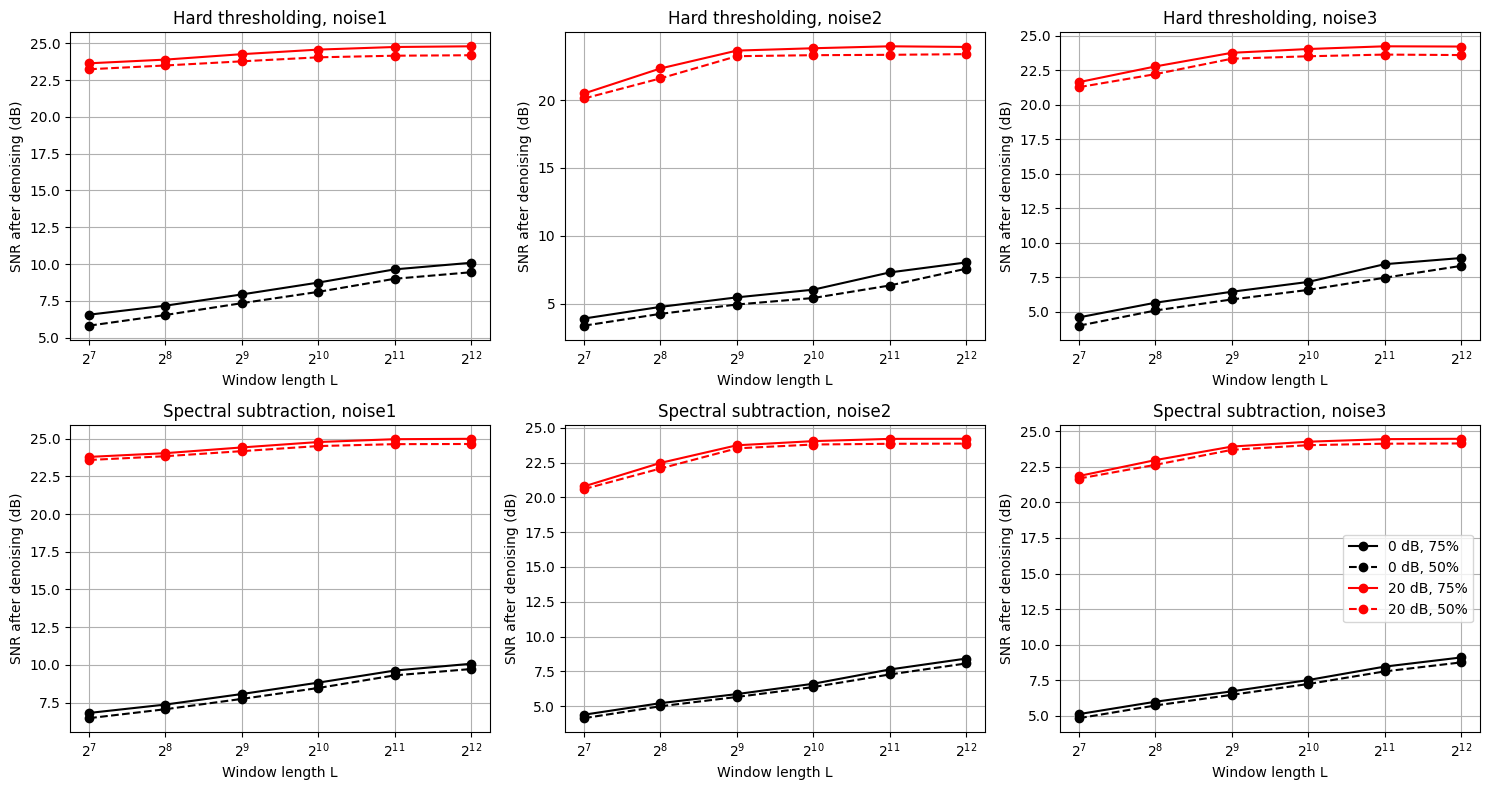

In [7]:
lengths = [128, 256, 512, 1024, 2048, 4096]
small_lams = [1.5, 2, 2.5, 3]
method_names = ["Hard thresholding", "Spectral subtraction"]
chosen_levels = [1, 5]
chosen_colors = ["k", "r"]

plt.figure(figsize=(15, 8))
for m in range(2):
    for k in range(3):
        plt.subplot(2, 3, 3 * m + k + 1)
        for n in range(2):
            i = chosen_levels[n]
            noise = scaled_noises[k][i]
            noisy = music + noise
            for overlap in [75, 50]:
                best_values = []
                for length in lengths:
                    step = length * (100 - overlap) // 100
                    Sn = noise_spectrum(noise, length, step)
                    best = -100
                    for lam in small_lams:
                        if m == 0:
                            denoised = hard_thresholding(noisy, Sn, lam, length, step)
                        else:
                            denoised = spectral_subtraction(noisy, Sn, lam, length, step)
                        value = snr(music, denoised)
                        if value > best:
                            best = value
                    best_values.append(best)

                text = ""
                for value in best_values:
                    text = text + str(round(value, 2)) + "  "
                print(method_names[m], names[k], targets[i], "dB, overlap", overlap, "%:", text)

                if overlap == 75:
                    plt.semilogx(lengths, best_values, "-o", color=chosen_colors[n], base=2, label=str(targets[i]) + " dB, 75%")
                else:
                    plt.semilogx(lengths, best_values, "--o", color=chosen_colors[n], base=2, label=str(targets[i]) + " dB, 50%")
        plt.title(method_names[m] + ", " + names[k])
        plt.xlabel("Window length L")
        plt.ylabel("SNR after denoising (dB)")
        plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

For both methods and the three noises, the SNR increases when the window is longer, for example from 6.8 to 10.1 dB between L = 128 and L = 4096 for spectral subtraction with noise1 at 0 dB. At 20 dB, it almost stops increasing after 2048, and it even goes down a bit for hard thresholding with noise2 and noise3.

The music is mostly made of held notes, that is sinusoids that last for a while. We can look at what happens for a sinusoid $x[t]=A\cos(2\pi\nu_0t)$ that does not change during the window. With $\cos\theta=\frac{e^{i\theta}+e^{-i\theta}}2$, its coefficient at frequency $\nu_0$ is:

$$X[\tau,\nu_0]=\sum_t A\cos(2\pi\nu_0t)\,w[t-a\tau]\,e^{-2i\pi\nu_0t}=\frac A2\sum_t w[t-a\tau]+\frac A2\sum_t w[t-a\tau]\,e^{-4i\pi\nu_0t}$$

If the window contains several periods, the second sum oscillates and stays small compared to the first one, so $|X[\tau,\nu_0]|\approx\frac A2\sum_t w[t]$. The sum of the window is proportional to $L$, so the power of the note is proportional to $L^2$. For a white noise of variance $\sigma^2$, the same computation as for $\mathbb E|B[k]|^2$ in the previous TP gives $S_n=\sigma^2\sum_t w[t]^2$, which is proportional to $L$. The ratio of the two is proportional to $L$, so with a longer window the notes go above the threshold more easily.

On the other hand, because of the uncertainty principle, a long window is less precise in time, so the note attacks are spread out. The global SNR does not show this problem well, we would need to listen to it. So we keep $L=1024$, which gives a good SNR with a window that is not too long.

The 75% overlap is always better than 50%, and the gap is bigger for hard thresholding, often around 0.5 dB, than for spectral subtraction, around 0.3 dB. We can think it is because each sample is rebuilt from four frames instead of two, so the "all or nothing" decisions of hard thresholding are averaged more.

### 4.3 Noise type and SNR level

We already saw in part 3 the effect of the level and the color of the noise. To see what a threshold that depends on the frequency is useful for, we do the denoising again with a constant spectrum, equal to the mean of $S_n$, which means assuming the noise is white. We keep the best $\lambda$. For noise1, which is white, it should not change anything.

In [8]:
for k in range(3):
    for i in [1, 5]:
        noise = scaled_noises[k][i]
        noisy = music + noise
        Sn = noise_spectrum(noise, L, hop)
        Sn_flat = np.ones(len(Sn)) * np.mean(Sn)

        best_hard = -100
        best_ss = -100
        for lam in lams:
            value = snr(music, hard_thresholding(noisy, Sn_flat, lam, L, hop))
            if value > best_hard:
                best_hard = value
            value = snr(music, spectral_subtraction(noisy, Sn_flat, lam, L, hop))
            if value > best_ss:
                best_ss = value

        print(names[k], targets[i], "dB: hard thresholding", round(np.max(results_hard[k, i]), 2), "dB with S_n(ν),", round(best_hard, 2), "dB with constant S_n",
              "/ spectral subtraction", round(np.max(results_ss[k, i]), 2), "dB with S_n(ν),", round(best_ss, 2), "dB with constant S_n")

noise1 0 dB: hard thresholding 8.81 dB with S_n(ν), 8.81 dB with constant S_n / spectral subtraction 8.82 dB with S_n(ν), 8.82 dB with constant S_n


noise1 20 dB: hard thresholding 24.66 dB with S_n(ν), 24.65 dB with constant S_n / spectral subtraction 24.77 dB with S_n(ν), 24.77 dB with constant S_n


noise2 0 dB: hard thresholding 6.09 dB with S_n(ν), 1.01 dB with constant S_n / spectral subtraction 6.61 dB with S_n(ν), 1.33 dB with constant S_n


noise2 20 dB: hard thresholding 23.94 dB with S_n(ν), 20.37 dB with constant S_n / spectral subtraction 24.04 dB with S_n(ν), 20.45 dB with constant S_n


noise3 0 dB: hard thresholding 7.2 dB with S_n(ν), 3.49 dB with constant S_n / spectral subtraction 7.51 dB with S_n(ν), 3.86 dB with constant S_n


noise3 20 dB: hard thresholding 24.09 dB with S_n(ν), 22.01 dB with constant S_n / spectral subtraction 24.29 dB with S_n(ν), 22.2 dB with constant S_n


As expected, for noise1 it changes nothing. For the colored noises however, the difference is big. For noise2 at 0 dB with hard thresholding, we go from about 1 dB with a constant threshold to about 6 dB with $S_n(\nu)$, and it is the same with spectral subtraction. With a constant threshold, we let the noise through at low frequencies, where it is strong, and we cut too much music at high frequencies, where it is weak.

### 4.4 Listening

We compare the spectrograms and the sound of the clean music, the noisy version and the two denoised versions, for noise3 at 5 dB, with the best $\lambda$ of each method. The spectrograms are in dB, with the same scale, up to 4 kHz.

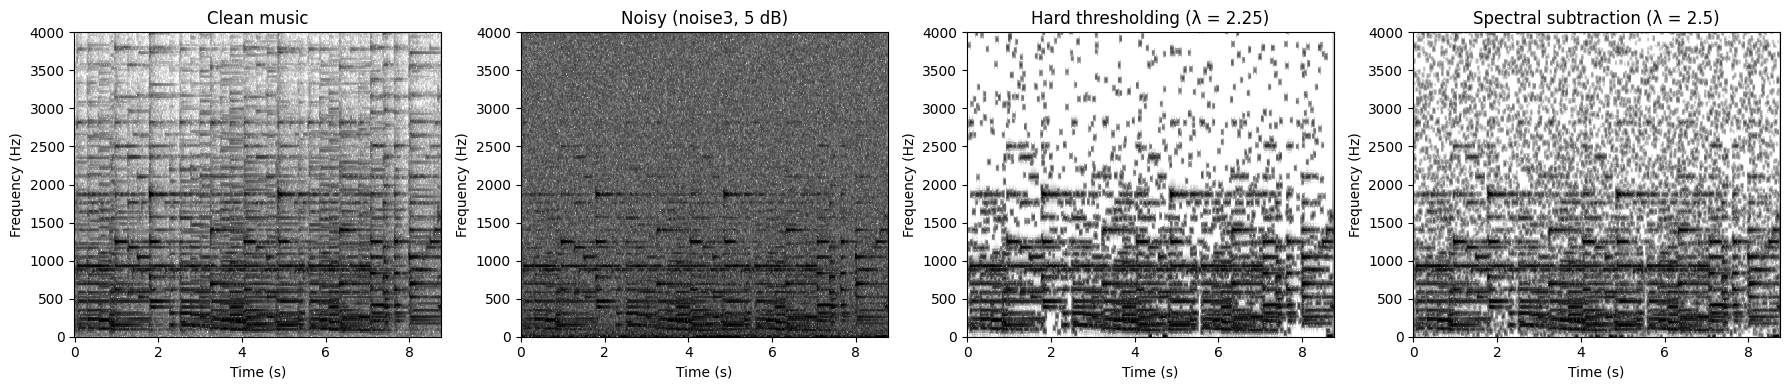

In [9]:
def show_spectrogram(x, title):
    f, t, X = signal.stft(x, fs, window="hann", nperseg=L, noverlap=L - hop)
    plt.pcolormesh(t, f, 20 * np.log10(np.abs(X) + 1e-8), vmin=-100, vmax=-20, cmap="gray_r")
    plt.ylim(0, 4000)
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.title(title)


noise = scaled_noises[2][2]
noisy = music + noise
Sn = noise_spectrum(noise, L, hop)
lam_hard = lams[np.argmax(results_hard[2, 2])]
lam_ss = lams[np.argmax(results_ss[2, 2])]
denoised_hard = hard_thresholding(noisy, Sn, lam_hard, L, hop)
denoised_ss = spectral_subtraction(noisy, Sn, lam_ss, L, hop)

plt.figure(figsize=(18, 4))
plt.subplot(1, 4, 1)
show_spectrogram(music, "Clean music")
plt.subplot(1, 4, 2)
show_spectrogram(noisy, "Noisy (noise3, 5 dB)")
plt.subplot(1, 4, 3)
show_spectrogram(denoised_hard, "Hard thresholding (λ = " + str(lam_hard) + ")")
plt.subplot(1, 4, 4)
show_spectrogram(denoised_ss, "Spectral subtraction (λ = " + str(lam_ss) + ")")
plt.tight_layout()
plt.show()

level = max(np.max(np.abs(noisy)), np.max(np.abs(denoised_hard)), np.max(np.abs(denoised_ss)))
display(Audio(music / level, rate=fs, normalize=False))
display(Audio(noisy / level, rate=fs, normalize=False))
display(Audio(denoised_hard / level, rate=fs, normalize=False))
display(Audio(denoised_ss / level, rate=fs, normalize=False))

On the two denoised spectrograms, the notes between 100 Hz and 2 kHz are well kept and the noise background is gone. Above 2 kHz, the music is too weak compared to the noise and it is almost completely removed. There is also some musical noise left, mostly at the top of the spectrum. It does not look the same depending on the method:

| | Hard thresholding | Spectral subtraction |
|---|---|---|
| Remaining noise points | few but very visible | more of them but lighter |
| Between the notes | completely white background (coefficients set to 0) | background with light gray points (coefficients reduced) |

The four players let us listen to the clean music, the noisy version and the two denoised versions, at the same volume.

## 5. Conclusion

Both methods improve the SNR well, by about 4 to 10 dB depending on the case, but a threshold that depends on the frequency is needed for the colored noises. Spectral subtraction is a bit better than hard thresholding in all cases, and above all it depends less on the choice of $\lambda$, because it reduces the coefficients little by little instead of keeping or removing them. The best settings we found are a $\lambda$ around 2.5, a fairly long window, from 1024 to 2048 samples, and 75% overlap. The problem of both methods is the musical noise, and the music that is lost where it is weaker than the noise.